<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/udlbook/Ch11_2_Residual_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Run this if you're in a Colab to install MNIST 1D repository
!pip install git+https://github.com/greydanus/mnist1d

  Cloning https://github.com/greydanus/mnist1d to /tmp/pip-req-build-9_zr6h5v
  Running command git clone --filter=blob:none --quiet https://github.com/greydanus/mnist1d /tmp/pip-req-build-9_zr6h5v
  Resolved https://github.com/greydanus/mnist1d to commit e2f536fa86442c13473b433d579e9852ec4d1c1d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import os
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import mnist1d
import random

## Loading the MNIST-1D Dataset

First, we retrieve the default dataset configuration using `get_dataset_args()`. These arguments define the parameters used to generate the MNIST-1D dataset.

Next, we load the dataset using `get_dataset()`. The `path` argument specifies the location of the saved dataset file. Setting `download=False` prevents downloading the dataset, while `regenerate=False` prevents generating it again from scratch.

The dataset is stored in a dictionary called `data`, which contains four main components:

- `data['x']`: Training input samples.
- `data['y']`: Labels corresponding to the training samples.
- `data['x_test']`: Test input samples.
- `data['y_test']`: Labels corresponding to the test samples.

Finally, we print some basic information about the dataset:

- **Examples in training set:** The number of training samples, obtained using `len(data['y'])`.
- **Examples in test set:** The number of test samples, obtained using `len(data['y_test'])`.
- **Length of each example:** The number of values in each input sample, obtained using `data['x'].shape[-1]`.

Since MNIST-1D consists of one-dimensional signals, each example is represented as a sequence of values rather than a two-dimensional image.

In [3]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=False)

print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Successfully loaded data from ./mnist1d_data.pkl
Examples in training set: 4000
Examples in test set: 1000
Length of each example: 40


## Loading and Preparing the Data

First, we load the training and validation data from the previously loaded dataset.

- `train_data_x`: Contains the training input samples. We use `.transpose()` to swap rows and columns, changing the shape from `(4000, 40)` to `(40, 4000)`.
- `train_data_y`: Contains the corresponding labels for the training samples.
- `val_data_x`: Contains the validation input samples. We also transpose this array to maintain the same data structure as the training inputs.
- `val_data_y`: Contains the corresponding labels for the validation samples.

After transposing, each **column represents one example**, while each **row represents one dimension (feature)** of that example.

Next, we print the sizes of the training and validation datasets:

Here, `%d` is a string formatting placeholder used to insert integer values into the text. The `%` operator substitutes the placeholders with the corresponding values.


In [4]:
train_data_x = data['x'].transpose()
train_data_y = data['y']
val_data_x = data['x_test'].transpose()
val_data_y = data['y_test']

print("Train data: %d examples (columns), each of which has %d dimensions (rows)"%((train_data_x.shape[1],train_data_x.shape[0])))
print("Validation data: %d examples (columns), each of which has %d dimensions (rows)"%((val_data_x.shape[1],val_data_x.shape[0])))

Train data: 4000 examples (columns), each of which has 40 dimensions (rows)
Validation data: 1000 examples (columns), each of which has 40 dimensions (rows)


## Building a Residual Neural Network

In this section, we define a Residual Neural Network (ResNet) using PyTorch. The model is based on a Multi-Layer Perceptron (MLP), but it includes residual connections (shortcut connections) around the hidden linear layers.

### 1. Defining Input and Output Dimensions

We define the input and output dimensions of the network:

- `D_i = 40`: Each input sample contains 40 dimensions (features).
- `D_o = 10`: The network produces 10 output values, corresponding to the 10 digit classes (0–9) in the MNIST-1D dataset.

### 2. Defining the Residual Network Class

We define a class called `ResidualNetwork` that inherits from `torch.nn.Module`.

In PyTorch, neural network models are typically defined by inheriting from `nn.Module`. This allows us to define and manage the network's layers and learnable parameters.

### 3. Initializing the Network

The `__init__()` method initializes the network when an instance of the class is created.

It accepts three parameters:

- `input_size`: Number of input dimensions.
- `output_size`: Number of output dimensions.
- `hidden_size`: Number of neurons in each hidden layer, with a default value of 100.

The `super()` function calls the constructor of the parent class (`torch.nn.Module`) to ensure that the model is properly initialized.

### 4. Defining the Linear Layers

We define four fully connected (linear) layers:

| Layer | Input Size | Output Size |
|---|---:|---:|
| `linear1` | 40 | 100 |
| `linear2` | 100 | 100 |
| `linear3` | 100 | 100 |
| `linear4` | 100 | 10 |

The first three layers operate in a 100-dimensional hidden space, while the final layer maps the hidden representation to 10 output values.

Keeping the hidden dimensions equal is important because residual connections require the tensors being added together to have compatible shapes.

### 5. Counting the Network Parameters

After initializing the layers, we print the total number of learnable parameters in the network.

The `count_params()` method performs this calculation:

- `self.parameters()` retrieves all learnable parameters of the network, including weights and biases.
- `p.view(-1)` reshapes each parameter tensor into a one-dimensional tensor.
- `.shape[0]` returns the number of elements in that tensor.
- `sum()` adds the number of elements across all parameter tensors.

Therefore, this method calculates the total number of weights and biases in the network.

### 6. Implementing the Forward Pass with Residual Connections

The `forward()` method defines how input data flows through the network.

Unlike a standard MLP, which passes information sequentially from one layer to the next, a residual network introduces shortcut connections that allow the input of a block to be added directly to its output.

A residual connection can be expressed mathematically as:
$
y=F(x)+x
$

where:
- $x$ is the input to the residual block.
- $F(x)$ represents the transformation performed by the block.
- $y$ is the resulting output after adding the original input.

These shortcut connections help gradients propagate through deeper networks and can reduce the vanishing gradient problem.

**The modified forward function is:**

Let's examine each step:

**Step 1. Initial Linear Transformation:**
The input is passed through the first linear layer, transforming it from the original input dimension (40) into a 100-dimensional hidden representation.

**Step 2. First Residual Block:**
Two paths are involved:

- Main path: The ReLU activation function is applied to `h1`, and the result is passed through `linear2`.
- Shortcut path: The original `h1` is added directly to the output of the main path.

Mathematically:
$
h_2=Linear_2(ReLU(h_1))+h_1
$

**Step 3. Second Residual Block:**
The same process is repeated using `h2` as the input:

- ReLU is applied to `h2`.
- The result passes through `linear3`.
- The original `h2` is added to the transformed output.

Mathematically:
$
h_3=Linear_3(ReLU(h_2))+h_2
$

**Step 4. Final Linear Transformation:**
Finally, the output of the second residual block is passed through `linear4`, producing 10 output values corresponding to the 10 digit classes.

>The main advantage of this architecture is that shortcut connections provide alternative paths for information and gradient propagation, making it easier to train deeper neural networks.Define the network

In [5]:
D_i = 40
D_o = 10

class ResidualNetwork(torch.nn.Module):
  def __init__(self, input_size, output_size, hidden_size=100):
    super(ResidualNetwork, self).__init__()
    self.linear1 = nn.Linear(input_size, hidden_size)
    self.linear2 = nn.Linear(hidden_size, hidden_size)
    self.linear3 = nn.Linear(hidden_size, hidden_size)
    self.linear4 = nn.Linear(hidden_size, output_size)
    print("Initialized MLPBase model with {} parameters".format(self.count_params()))

  def count_params(self):
    return sum([p.view(-1).shape[0] for p in self.parameters()])

  def forward(self, x):
    h1 = self.linear1(x)
    h2 = self.linear2(h1.relu()) + h1
    h3 = self.linear3(h2.relu()) + h2
    return self.linear4(h3)

## He Initialization of Weights

In this section, we define a function to initialize the weights and biases of the neural network using **He Initialization (Kaiming Initialization)**.

The purpose of this initialization method is to choose appropriate initial weight values so that the scale of signals and gradients can be better maintained as they propagate through the network.

### 1. Defining the Initialization Function

We define a function called `weights_init` that takes a neural network layer as its input.

This function is responsible for initializing the weights and biases of the specified layer.

### 2. Checking the Layer Type

The `isinstance()` function checks whether `layer_in` is an instance of `nn.Linear`.

We use this condition because we only want to apply the initialization procedure to fully connected (linear) layers.

### 3. Initializing the Weights Using He Initialization

Here, we use `kaiming_uniform_()` to initialize the weights using **Kaiming Uniform Initialization**, also known as He Initialization.

This method initializes weights using a uniform distribution, with a range determined by the number of input connections (`fan_in`) of each layer.

For the default ReLU-compatible Kaiming Uniform initialization, the weights are sampled from:
$
W \sim U\left(
-\sqrt{\frac{6}{fan\_in}},
+\sqrt{\frac{6}{fan\_in}}
\right)
$

The main purpose of this method is to maintain a suitable scale for activations as information passes through multiple layers.

In deep neural networks, inappropriate weight initialization can cause activations and gradients to become extremely small or excessively large, contributing to problems such as:

- **Vanishing Gradients:** Gradients become too small during backpropagation.
- **Exploding Gradients:** Gradients become excessively large during backpropagation.

He Initialization is particularly suitable for networks that use the ReLU activation function because it accounts for the effect of ReLU on the distribution of activations.

### 4. Initializing the Biases

Here, we initialize all bias values of the linear layer to **zero**.

- `layer_in.bias`: Accesses the bias parameters of the layer.
- `.data`: Accesses the underlying tensor data.
- `.fill_(0.0)`: Fills all elements of the bias tensor with zeros.

The underscore at the end of `fill_()` indicates that the operation is performed in-place, meaning that the existing tensor is modified directly.

In [6]:
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

## Training the Residual Neural Network

In this section, we configure and train the Residual Neural Network using the MNIST-1D dataset. We define the loss function, optimizer, and learning rate scheduler, prepare the data, and implement the training loop. We also evaluate the model's performance on both the training and validation datasets after each epoch.

### 1. Defining the Model

We create an instance of the `ResidualNetwork` class defined earlier.

The model receives two arguments:

- `40`: Number of input dimensions.
- `10`: Number of output dimensions, corresponding to the 10 digit classes.

The default hidden layer size is 100 neurons.

### 2. Defining the Loss Function

We use `CrossEntropyLoss` to measure the difference between the model's predictions and the actual class labels.

Since MNIST-1D is a classification problem with 10 classes, Cross Entropy is an appropriate loss function.

This loss function expects raw model outputs (logits) and automatically performs the necessary LogSoftmax and Negative Log-Likelihood calculations internally. Therefore, we do not need to apply Softmax separately before computing the loss.

### 3. Defining the Optimizer

We use Stochastic Gradient Descent (SGD) to update the model's learnable parameters.

The parameters are:

- `model.parameters()`: Provides the optimizer with all learnable weights and biases.
- `lr=0.05`: Sets the initial learning rate to 0.05.
- `momentum=0.9`: Uses a momentum coefficient of 0.9.

Momentum considers information from previous gradient updates in addition to the current gradient. This can help accelerate convergence and reduce fluctuations during optimization.

### 4. Defining the Learning Rate Scheduler

We use `StepLR` to reduce the learning rate during training.

The parameters are:

- `optimizer`: The SGD optimizer defined earlier.
- `step_size=20`: Reduces the learning rate every 20 epochs.
- `gamma=0.5`: Multiplies the learning rate by 0.5 at each update.

Starting with an initial learning rate of 0.05, the learning rate changes as follows:

| Epochs | Learning Rate |
|---|---:|
| 1–20 | 0.05 |
| 21–40 | 0.025 |
| 41–60 | 0.0125 |
| 61–80 | 0.00625 |
| 81–100 | 0.003125 |

This allows the model to take larger optimization steps initially and smaller steps during later stages of training.

### 5. Converting the Data into PyTorch Tensors

In this step, we convert the NumPy arrays into PyTorch tensors so they can be used by the neural network.

For the input data:

- `transpose()`: Changes the arrangement of rows and columns back to the original structure, placing examples in rows and features in columns.
- `astype('float32')`: Converts the input values into 32-bit floating-point numbers.
- `torch.tensor()`: Converts the NumPy array into a PyTorch tensor.

For the target labels:

- `astype('long')`: Converts the labels into 64-bit integers.
- `torch.tensor()`: Converts the labels into PyTorch tensors.

The `long` data type is required by `CrossEntropyLoss` when using class indices as targets.

The same operations are performed for both training and validation datasets.

### 6. Creating the DataLoader

We use `TensorDataset` and `DataLoader` to organize the training data into smaller batches.

**TensorDataset:**
`
TensorDataset(x_train, y_train)
`
Combines the input samples and their corresponding labels into a single dataset. Each input sample remains paired with its correct target label.

**DataLoader:**
The `DataLoader` retrieves samples from the dataset in batches.

Its main parameters are:

- `batch_size=100`: Each batch contains 100 training examples.
- `shuffle=True`: Randomly shuffles the training samples at the beginning of each epoch.

For example, if the training dataset contains 4,000 examples and the batch size is 100:
Therefore, the model processes 40 batches during each epoch.

> **Note:** The expression `np.random.seed(1)` is executed immediately and returns `None`, which is passed to `worker_init_fn`. It does not actually provide a worker initialization function. Since `num_workers` defaults to zero, no separate data-loading workers are used here.

### 7. Initializing the Model Weights

We apply the previously defined `weights_init()` function to the model.

This initializes the parameters of all linear layers:

- Weights are initialized using Kaiming Uniform Initialization.
- Biases are initialized to zero.

This step is performed before training so that the model starts with appropriately initialized parameters.

### 8. Setting the Number of Epochs

We set the number of training epochs to 100.
An epoch represents one complete pass through the entire training dataset.
Therefore, the model will go through the training dataset 100 times.

### 9. Initializing Arrays to Store Performance Metrics

We create four NumPy arrays to store the model's performance metrics after each epoch.

The `np.zeros()` function creates arrays filled with zeros.

Each array contains 100 elements, corresponding to the 100 training epochs.

| Variable | Description |
|---|---|
| `losses_train` | Training loss at each epoch |
| `errors_train` | Training error percentage at each epoch |
| `losses_val` | Validation loss at each epoch |
| `errors_val` | Validation error percentage at each epoch |

These arrays allow us to monitor the training process and plot the loss and error curves later.

### 10. Implementing the Training Loop

This is the main training loop.
Since `n_epoch` is set to 100, the loop executes 100 times. Each iteration represents one complete epoch.

#### 10.1. Iterating Through Training Batches

`
for i, data in enumerate(data_loader):
`
This loop iterates over all batches provided by the `DataLoader`.

- `i`: The index of the current batch.
- `data`: The input samples and corresponding labels in that batch.

The `enumerate()` function provides both the index and the data for each iteration.

#### 10.2. Retrieving Inputs and Labels

`
x_batch, y_batch = data
`
Each batch contains two components:

- `x_batch`: Input samples.
- `y_batch`: Corresponding target labels.

With a batch size of 100, each batch normally contains 100 input examples and 100 labels.

#### 10.3. Zeroing the Gradients

Before calculating new gradients, we reset the gradients from the previous batch to zero.

PyTorch accumulates gradients by default. Therefore, without this operation, gradients from previous batches would be added to the gradients of the current batch.

We use `zero_grad()` to prevent this unwanted accumulation.

#### 10.4. Performing the Forward Pass

`
pred = model(x_batch)
`
We pass the current batch through the neural network.

The model processes the inputs through its linear layers and residual connections and produces 10 output values (logits) for each example.

For a batch containing 100 examples, the output shape is:
$
pred.shape=(100,10)
$

Each row represents one example, and each column corresponds to one of the 10 classes.

#### 10.5. Computing the Loss

We calculate the loss by comparing the model's predictions with the actual labels.

The `CrossEntropyLoss` function measures how well the predicted class scores match the correct target classes.

A lower loss generally indicates better predictions.

#### 10.6. Performing the Backward Pass

`
loss.backward()
`
Here, we perform backpropagation.

PyTorch calculates the gradients of the loss with respect to all learnable parameters of the network.

These gradients indicate how changes in the weights and biases affect the loss and are used by the optimizer to update the model parameters.

### 10.7. Updating the Model Parameters

`
optimizer.step()

The optimizer uses the calculated gradients to update the weights and biases of the network.

Since we are using SGD with momentum, the parameter updates take both the current gradients and previous update information into account.

### 11. Evaluating the Model After Each Epoch

After processing all training batches in an epoch, we evaluate the model on the entire training and validation datasets.

`
pred_train = model(x_train)
`
`
pred_val = model(x_val)
`

We pass the complete training and validation datasets through the model.

- `pred_train`: Predictions for all training examples.
- `pred_val`: Predictions for all validation examples.

Unlike the training loop, where data is processed in batches, here we evaluate the entire datasets at once to calculate overall performance metrics.

#### 11.1. Extracting the Predicted Classes

The network produces 10 output values for each example.

To determine the predicted class, we select the index of the largest output value.

The `torch.max()` function returns two values:

1. The maximum value.
2. The index of that maximum value.

The argument `1` specifies that the maximum should be calculated along the second dimension, which represents the 10 classes.

We use `_` to ignore the maximum values because we only need their indices.

Therefore:

- `predicted_train_class`: Predicted classes for the training examples.
- `predicted_val_class`: Predicted classes for the validation examples.

#### 11.2. Calculating Training Error

We calculate the percentage of incorrect predictions on the training dataset.

First:
We compare the predicted classes with the actual labels.
This produces a Boolean tensor:

- `True`: The prediction is correct.
- `False`: The prediction is incorrect.

Next:
We convert the Boolean values into floating-point numbers:

- `True` becomes 1.
- `False` becomes 0.

Then, `sum()` counts the number of correct predictions.

Next, we divide the number of correct predictions by the total number of training examples:
$
Accuracy=\frac{\text{Correct Predictions}}{\text{Total Examples}}\times100
$

Finally, we subtract the accuracy from 100 to obtain the error percentage:
$
Error=100-Accuracy
$

The resulting error percentage is stored in `errors_train[epoch]`.

#### 11.3. Calculating Validation Error

This operation is identical to the training error calculation, but it is performed on the validation dataset.
The resulting validation error percentage is stored in `errors_val[epoch]`.

#### 11.4. Calculating Training and Validation Loss

Here, we calculate the loss over the entire training and validation datasets.

- `loss_function(pred_train, y_train)`: Calculates the training loss.
- `loss_function(pred_val, y_val)`: Calculates the validation loss.
- `.item()`: Converts a single-element PyTorch tensor into a standard Python number.

The results are stored in their corresponding arrays.

Unlike the loss calculation inside the training loop, which is performed separately for each batch, these calculations measure the loss over the complete datasets.

### 12. Printing the Results of Each Epoch

We print the performance metrics after each epoch using an f-string.

The formatting specifications include:

- `{epoch:5d}`: Displays the epoch number as an integer with a minimum width of 5 characters.
- `{losses_train[epoch]:.6f}`: Displays the training loss with 6 decimal places.
- `{errors_train[epoch]:3.2f}`: Displays the training error with 2 decimal places.
- `{losses_val[epoch]:.6f}`: Displays the validation loss with 6 decimal places.
- `{errors_val[epoch]:3.2f}`: Displays the validation error with 2 decimal places.

This allows us to monitor how the model's performance changes throughout training.

### 13. Updating the Learning Rate

`
scheduler.step()
`
At the end of each epoch, we call `scheduler.step()` to update the learning rate if necessary.

Based on the scheduler configuration:
`
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)
`

The learning rate is reduced by half every 20 epochs.

This allows the model to use larger optimization steps during the early stages of training and smaller steps during later stages.

> **Important:** Monitoring both training and validation performance helps us understand how well the model learns and generalizes to unseen data. Comparing these metrics can also help identify overfitting, which occurs when the model performs well on training data but poorly on validation data.

In [7]:
model = ResidualNetwork(40, 10)

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)

scheduler = StepLR(optimizer, step_size=20, gamma=0.5)

x_train = torch.tensor(train_data_x.transpose().astype('float32'))
y_train = torch.tensor(train_data_y.astype('long'))
x_val= torch.tensor(val_data_x.transpose().astype('float32'))
y_val = torch.tensor(val_data_y.astype('long'))

data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

model.apply(weights_init)

n_epoch = 100

losses_train = np.zeros((n_epoch))
errors_train = np.zeros((n_epoch))
losses_val = np.zeros((n_epoch))
errors_val = np.zeros((n_epoch))

for epoch in range(n_epoch):
  for i, data in enumerate(data_loader):

    x_batch, y_batch = data
    optimizer.zero_grad()
    pred = model(x_batch)
    loss = loss_function(pred, y_batch)
    loss.backward()
    optimizer.step()

  pred_train = model(x_train)
  pred_val = model(x_val)

  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_val_class = torch.max(pred_val.data, 1)

  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_val[epoch]= 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)

  losses_train[epoch] = loss_function(pred_train, y_train).item()
  losses_val[epoch]= loss_function(pred_val, y_val).item()

  print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

  scheduler.step()

Initialized MLPBase model with 25310 parameters
Epoch     0, train loss 1.612386, train error 59.83,  val loss 1.729570, percent error 63.40
Epoch     1, train loss 1.201420, train error 47.38,  val loss 1.349915, percent error 52.50
Epoch     2, train loss 0.995903, train error 37.22,  val loss 1.198240, percent error 44.90
Epoch     3, train loss 0.913056, train error 34.55,  val loss 1.177190, percent error 44.00
Epoch     4, train loss 0.836045, train error 32.40,  val loss 1.180515, percent error 43.30
Epoch     5, train loss 0.708506, train error 26.68,  val loss 1.097043, percent error 40.10
Epoch     6, train loss 0.715813, train error 25.97,  val loss 1.212651, percent error 41.90
Epoch     7, train loss 0.668530, train error 25.25,  val loss 1.223877, percent error 39.50
Epoch     8, train loss 0.615405, train error 24.22,  val loss 1.207866, percent error 40.70
Epoch     9, train loss 0.586458, train error 20.70,  val loss 1.320837, percent error 39.70
Epoch    10, train los

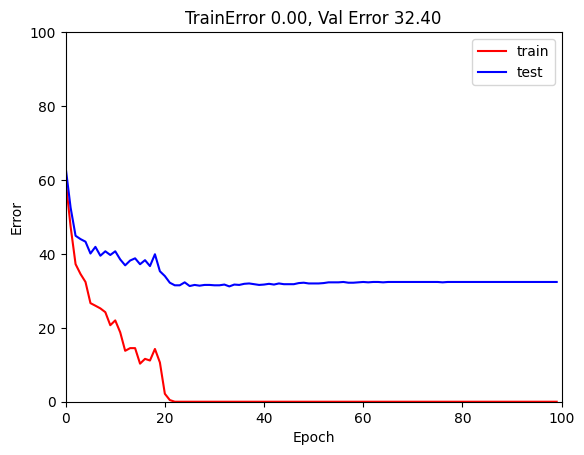

In [8]:
# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_val,'b-',label='test')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('TrainError %3.2f, Val Error %3.2f'%(errors_train[-1],errors_val[-1]))
ax.legend()
plt.show()

The results indicate **severe overfitting**. Initially, both training and validation errors decrease as the number of epochs increases. However, after approximately Epoch 20, the training error reaches zero, while the validation error remains around 30–31%. Furthermore, the validation loss starts increasing after the first few epochs and reaches 1.636 by the end of training. This suggests that the model has become overly adapted to the training data instead of learning patterns that generalize well to unseen data. Consequently, despite achieving 100% accuracy on the training set, its validation accuracy is only about 69%. Continuing training does not improve the model's generalization performance.



---



## Q: Compare the results of the residual network with those of the network without residual connections. What can you conclude?

Both models exhibit **overfitting**, but the residual network achieves better performance on the validation set.

| Metric | With Residual Connections | Without Residual Connections |
|---|---:|---:|
| Number of parameters | 25,310 | 25,310 |
| Best Validation Error | 30.2% | 32.8% |
| Final Validation Error | 30.9% | 34.8% |
| Final Training Error | 0% | 0% |
| Final Validation Loss | 1.636 | 2.117 |

**Analysis:**

In the network without residual connections, the training error reaches zero around Epoch 24, while the validation error reaches its minimum of 32.8% and then increases to 34.8% by the final epoch. The validation loss also increases continuously, indicating overfitting.

In contrast, the residual network achieves a lower validation error (30.2%) and a lower final validation loss (1.636 compared to 2.117).

**Conclusion:**

Both models successfully fit the training data, but the residual network generalizes better to unseen data. Therefore, in this experiment, residual connections help improve generalization, although they do not completely prevent overfitting.

> *Note: The same code, hyperparameters, and training settings were used for both experiments. The only difference was the removal of the residual connections (+ h1 and + h2) in the second model. However, differences in random weight initialization and data shuffling may still affect the results.*